# Politeia - Exploratory Data Analysis de fuentes

Este notebook explora IDEA, las tablas de series temporales de AmericasBarometer, V-Dem v16 y los PDFs metodologicos


In [1]:
from pathlib import Path
import re
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "boceto.md").exists():
    ROOT = Path(r"C:\Users\anapa\OneDrive\Escritorio\facu\politeia")
print(ROOT)


c:\Users\anapa\OneDrive\Escritorio\facu\politeia


## 1. Inventario


In [2]:
inventory = pd.DataFrame([
    {"file": p.name, "extension": p.suffix.lower(), "size_mb": round(p.stat().st_size / 1024**2, 3)}
    for p in sorted(ROOT.iterdir()) if p.is_file()
])
display(inventory)


,file,extension,size_mb
0,.gitignore,,0.000
1,api-publicacion-resultados-electorales.yaml,.yaml,0.006
2,arg_parlamentary.xlsx,.xlsx,0.008
3,arg_presidential.xlsx,.xlsx,0.008
4,boceto.md,.md,0.002
5,cautionary_notes_vdem.pdf,.pdf,0.175
6,chile_parlamentary.xlsx,.xlsx,0.007
7,chile_presidential.xlsx,.xlsx,0.008
8,codebook_vdem.pdf,.pdf,3.450
9,dine_api.py,.py,0.006


## 2. IDEA - libros electorales

Se combinan los ocho libros y se agregan pais y tipo de eleccion desde el nombre del archivo.


In [3]:
idea_frames = []
for path in sorted(ROOT.glob("*.xlsx")):
    raw = pd.read_excel(path, header=None)
    raw.columns = raw.iloc[0].astype(str).str.strip()
    df = raw.iloc[1:].reset_index(drop=True)
    stem = path.stem.lower()
    df["country"] = stem.split("_")[0].upper()
    df["election_type"] = "presidential" if "presidential" in stem else "parliamentary"
    idea_frames.append(df)
idea = pd.concat(idea_frames, ignore_index=True)
idea.columns = [str(c).strip().lower().replace(" ", "_") for c in idea.columns]
# IDEA stores percentages and counts as formatted strings; parse them explicitly.
for col in ["voter_turnout", "vap_turnout", "invalid_votes"]:
    if col in idea:
        idea[col] = (idea[col].astype(str).str.replace("%", "", regex=False).str.replace(",", "", regex=False).str.strip())
        idea[col] = pd.to_numeric(idea[col], errors="coerce")
for col in ["total_vote", "registration", "voting_age_population", "population"]:
    if col in idea:
        idea[col] = pd.to_numeric(idea[col].astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
idea["year"] = pd.to_datetime(idea["year"], errors="coerce").dt.year
print("shape:", idea.shape)
display(idea.head())
display(idea.dtypes.to_frame("dtype"))
display(idea.isna().mean().sort_values(ascending=False).to_frame("missing_rate"))
display(idea.groupby(["country", "election_type"]).agg(year_min=("year","min"), year_max=("year","max"), observations=("year","count"), turnout_mean=("voter_turnout","mean")).round(2))


shape: (156, 11)


,year,voter_turnout,total_vote,registration,vap_turnout,voting_age_population,population,invalid_votes,compulsory_voting,country,election_type
0,1946,83.39,2839507,3405173.0,28.34,10018560,15654000,2.5,Yes,ARG,parliamentary
1,1951,87.95,7593948,8633998.0,67.28,11286400,17635000,1.6,Yes,ARG,parliamentary
2,1954,86.00,7906858,9194157.0,65.92,11994880,18742000,2.0,Yes,ARG,parliamentary
3,1958,90.86,9088497,10002327.0,70.80,12837120,20058000,9.2,Yes,ARG,parliamentary
4,1960,87.07,8870202,10187586.0,67.06,13228160,20669000,25.2,Yes,ARG,parliamentary


,dtype
year,int32
voter_turnout,float64
total_vote,int64
registration,float64
vap_turnout,float64
voting_age_population,int64
population,int64
invalid_votes,float64
compulsory_voting,str
country,str


,missing_rate
invalid_votes,0.141026
registration,0.032051
voter_turnout,0.032051
total_vote,0.000000
year,0.000000
voting_age_population,0.000000
vap_turnout,0.000000
population,0.000000
compulsory_voting,0.000000
country,0.000000


year_min  year_max  observations  turnout_mean
country election_type                                                
ARG     parliamentary      1946      2025            30         80.88
        presidential       1946      2023            18         82.37
CHILE   parliamentary      1945      2025            18         75.41
        presidential       1946      2025            21         75.81
PAR     parliamentary      1953      2023            16         73.33
        presidential       1953      2023            16         73.70
URU     parliamentary      1946      2024            16         83.05
        presidential       1946      2024            21         84.16

In [4]:
# Cortar a partir del retorno a la democracia en cada país

demo_arg, demo_chile, demo_par, demo_uru = 1983, 1990, 1989, 1985

idea = idea[~(
    ((idea["country"] == "ARG") & (idea["year"] < demo_arg)) |
    ((idea["country"] == "CHILE") & (idea["year"] < demo_chile)) |
    ((idea["country"] == "PAR") & (idea["year"] < demo_par  )) |
    ((idea["country"] == "URU") & (idea["year"] < demo_uru))
)]


In [5]:
idea.head(15)

,year,voter_turnout,total_vote,registration,vap_turnout,voting_age_population,population,invalid_votes,compulsory_voting,country,election_type
9,1983,83.25,14927572,17929951.0,77.52,19257550,29627000,2.50,Yes,ARG,parliamentary
10,1985,82.19,15326907,18649101.0,77.76,19711250,30325000,2.00,Yes,ARG,parliamentary
11,1987,83.61,16263572,19452790.0,80.14,20293650,31221000,5.30,Yes,ARG,parliamentary
12,1989,84.24,16867095,20022072.0,82.07,20552960,32114000,2.10,Yes,ARG,parliamentary
13,1991,89.71,18609221,20742631.0,89.41,20812743,32863366,7.70,Yes,ARG,parliamentary
14,1993,79.70,17090830,21443953.0,78.09,21886150,33671000,6.90,Yes,ARG,parliamentary
15,1995,80.96,17939156,22158612.0,79.77,22488050,34597000,3.70,Yes,ARG,parliamentary
16,1997,78.22,18135267,23184491.0,78.07,23230160,35739000,6.20,Yes,ARG,parliamentary
17,2001,75.21,18602837,24735483.0,72.99,25487913,37694169,21.00,Yes,ARG,parliamentary
18,2005,73.33,19168566,26140766.0,73.23,26175246,39537943,10.02,Yes,ARG,parliamentary


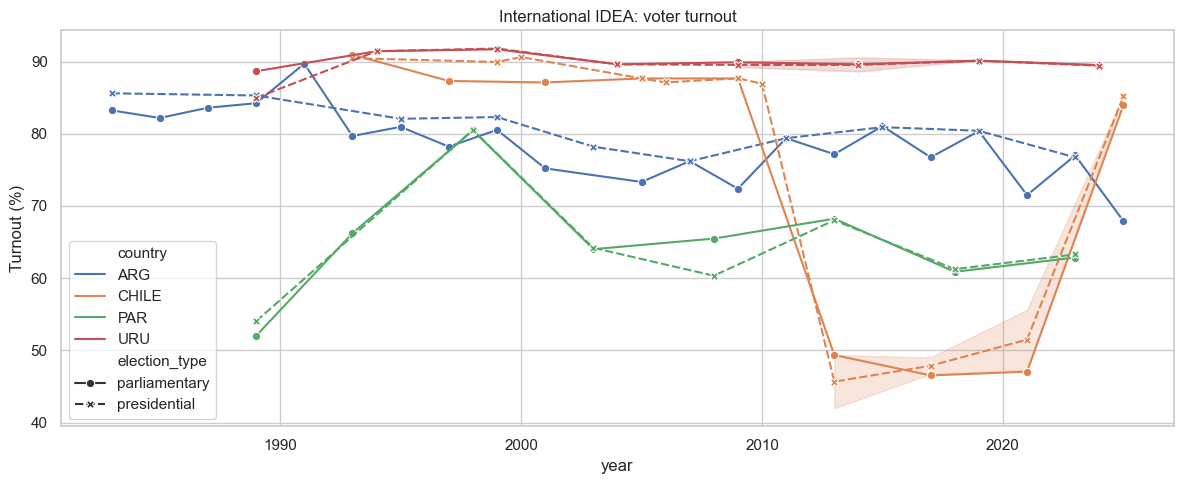

In [6]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=idea, x="year", y="voter_turnout", hue="country", style="election_type", markers=True)
plt.title("International IDEA: voter turnout")
plt.ylabel("Turnout (%)")
plt.tight_layout()
plt.show()


## 3. AmericasBarometer - tablas de series temporales

La fuente esta organizada como archivos `ts_{indicator_code}`. Cada archivo contiene una estimacion por ola (`prop`), limites inferior y superior del intervalo (`lb`, `ub`), error estandar y etiqueta. Se cargan exclusivamente los diez codigos definidos para Politeia.


In [7]:
# AmericasBarometer time-series tables: one CSV per indicator code.
AB_INDICATORS = {
    "cp8": "Attendance at Meetings for Community Improvements",
    "cp13": "Attendance at Meetings of Political Parties",
    "np1": "Attendance at Municipal Meeting",
    "gi0n": "Frequency of Watching News",
    "vb10": "Identifies with a Political Party",
    "pol1": "Political Interest",
    "pn4": "Satisfaction with Democracy",
    "ing4": "Support for Democracy",
    "eff1": "Leaders Are Interested in What People Think",
    "b4": "Pride in Political System",
}

def indicator_path(code):
    matches = sorted(ROOT.glob(f"ts_{code}*.csv"))
    if not matches:
        raise FileNotFoundError(f"Missing time-series table for {code}")
    return matches[0]

ab_frames = []
for code, meaning in AB_INDICATORS.items():
    matches = sorted(ROOT.glob(f"ts_{code}*.csv"))
    if not matches:
        warnings.warn(f"Skipping unavailable AmericasBarometer table: {code}")
        continue
    path = indicator_path(code)
    df = pd.read_csv(path)
    df["indicator_code"] = code
    df["indicator"] = meaning
    df["source_file"] = path.name
    df["wave"] = pd.to_numeric(df["wave"], errors="coerce")
    ab_frames.append(df)
ab = pd.concat(ab_frames, ignore_index=True)
print("AmericasBarometer shape:", ab.shape)
display(ab.head())
display(ab.groupby(["indicator_code", "indicator"]).agg(waves=("wave", "count"), wave_min=("wave", "min"), wave_max=("wave", "max"), mean=("prop", "mean"), missing=("prop", lambda s: s.isna().sum())).round(2))


AmericasBarometer shape: (89, 10)


,wave,prop,lb,ub,se,proplabel,empty,indicator_code,indicator,source_file
0,2008.0,17.302452,14.560962,20.043943,1.398745,17%,1,cp8,Attendance at Meetings for Community Improvements,ts_cp8.csv
1,2010.0,14.849354,12.115875,17.582834,1.394658,15%,1,cp8,Attendance at Meetings for Community Improvements,ts_cp8.csv
2,2012.0,8.843085,6.755595,10.930575,1.065065,9%,1,cp8,Attendance at Meetings for Community Improvements,ts_cp8.csv
3,2014.0,8.915502,7.191536,10.639469,0.879591,9%,1,cp8,Attendance at Meetings for Community Improvements,ts_cp8.csv
4,NaN,10.426230,8.692912,12.159547,0.884362,10%,1,cp8,Attendance at Meetings for Community Improvements,ts_cp8.csv


,,waves,wave_min,wave_max,mean,missing
indicator_code,indicator,,,,,
b4,Pride in Political System,6,2008.0,2023.0,41.59,0
cp13,Attendance at Meetings of Political Parties,6,2008.0,2023.0,10.05,2
cp8,Attendance at Meetings for Community Improvements,6,2008.0,2023.0,11.16,1
eff1,Leaders Are Interested in What People Think,7,2008.0,2026.0,29.24,1
gi0n,Frequency of Watching News,6,2010.0,2026.0,85.55,0
ing4,Support for Democracy,8,2006.0,2026.0,63.85,0
np1,Attendance at Municipal Meeting,7,2006.0,2023.0,10.91,1
pn4,Satisfaction with Democracy,8,2006.0,2026.0,47.83,0
pol1,Political Interest,7,2008.0,2026.0,39.86,1


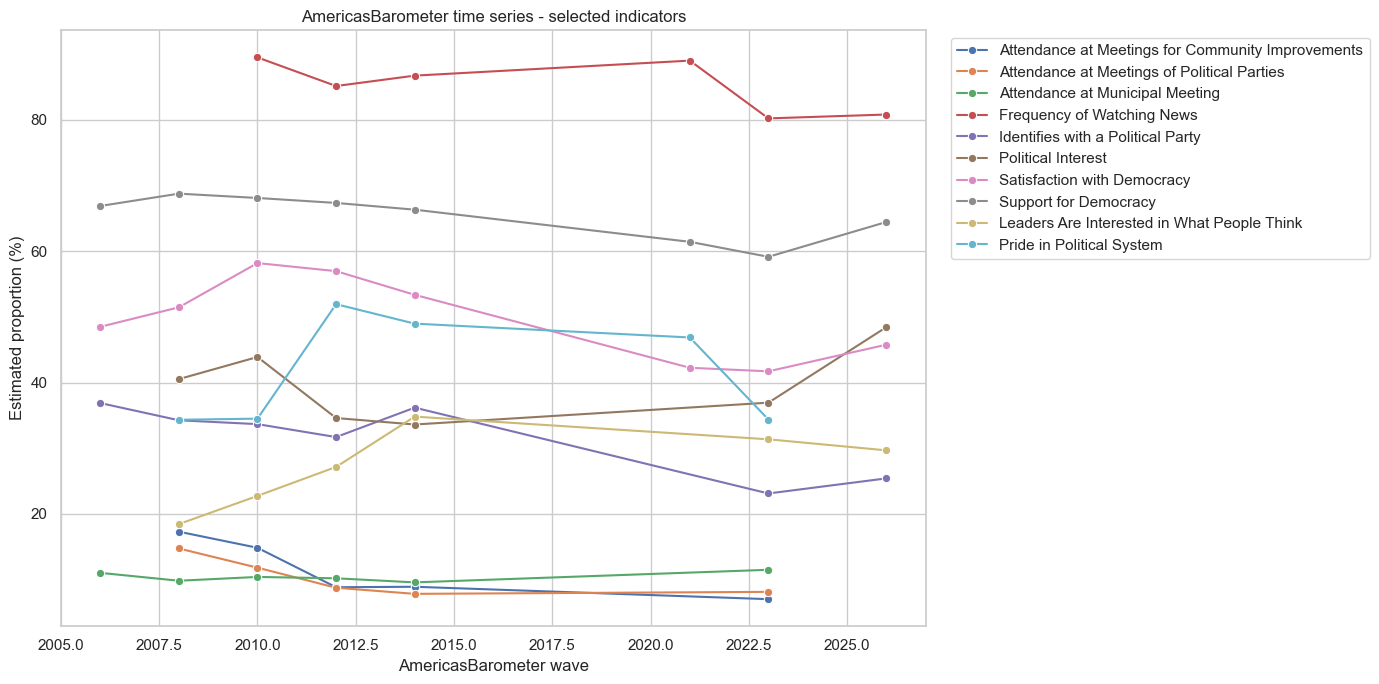

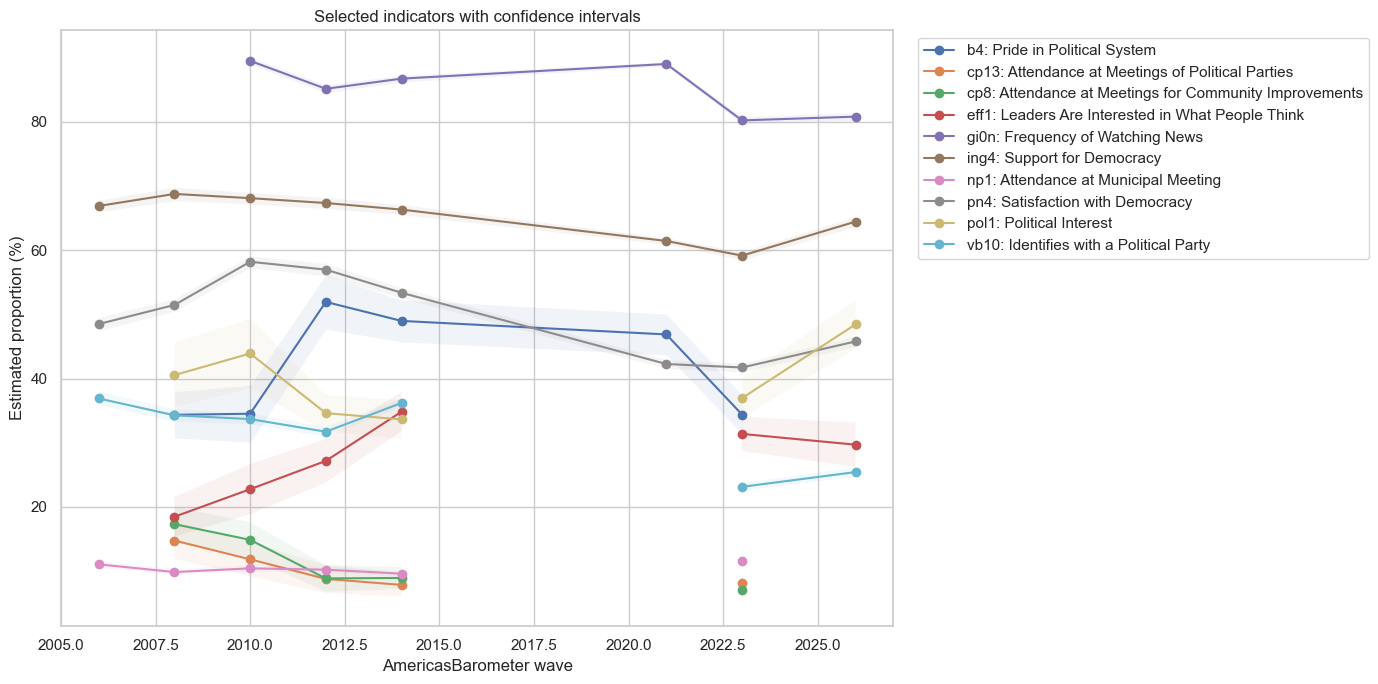

In [8]:
plt.figure(figsize=(14, 7))
sns.lineplot(data=ab, x="wave", y="prop", hue="indicator", marker="o")
plt.ylabel("Estimated proportion (%)")
plt.xlabel("AmericasBarometer wave")
plt.title("AmericasBarometer time series - selected indicators")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Confidence intervals supplied by the source tables.
plt.figure(figsize=(14, 7))
for code, group in ab.groupby("indicator_code"):
    group = group.sort_values("wave")
    plt.plot(group["wave"], group["prop"], marker="o", label=f"{code}: {AB_INDICATORS[code]}")
    plt.fill_between(group["wave"], group["lb"], group["ub"], alpha=0.08)
plt.ylabel("Estimated proportion (%)")
plt.xlabel("AmericasBarometer wave")
plt.title("Selected indicators with confidence intervals")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


- cp8: Attendance at Meetings for Community Improvements
    - CP8. Please tell me if you attend meetings of these organizations at least once a week, once or twice a month, once or twice a year, or never. Meetings of a community improvement committee or association? Do you attend them...
    (1) Never (2) Once or twice a month (3) Once or twice a year (4) Once a week
    - Se toman 2 en adelante
- cp13: Attendance at Meetings of Political Parties
  - CP13. Please tell me if you attend meetings of these organizations at least once a week, once or twice a month, once or twice a year, or never. Meetings of a political party or political organization? Do you attend them...
  (1) Never (2) Once or twice a month (3) Once or twice a year (4) Once a week
  - Se toman 2 en adelante
- np1: Attendance at Municipal Meeting
  - NP1. Have you attended a [local meeting] during the last 12 months?(1) No (2) Yes
  - Se toma 2
- gi0n: Frequency of Watching News
  - GI0N. About how often do you pay attention to the news, whether on TV, the radio, newspapers or the internet? (1) Never (2) Rarely/A few times a year (3) A few times a month (4) A few times a week (5) Daily
  - Se toman 4 y 5
- vb10: Identifies with a Political Party, pol1: Political Interest
  - VB10. Do you currently identify with a political party? (1) No (2) Yes
  - Se toma el 2
- pol1: Interes in politics:
  - POL1. How much interest do you have in politics? (1) None (2) Little (3) Some (4) A lot
  - Se toma 3 y 4
- pn4: Satisfaction with Democracy
  - PN4. In general, would you say that you are very satisfied, satisfied, dissatisfied or very dissatisfied with the way democracy works in (country)? (1) Very dissatisfied (2) Dissatisfied (3) Satisfied (4) Very satisfied
  - Se toman 3 y 4
- ing4: Support for Democracy
  - ING4. Changing the subject again, democracy may have problems, but it is better than any other form of government. To what extent do you agree or disagree with this statement? (1) Strongly disagree (2) (3) (4) (5) (6) (7) Strongly agree
  - Se toman 5, 6, y 7
- eff1: Leaders Are Interested in What People Think
  - EFF1. Those who govern this country are interested in what people like you think. How much do you agree or disagree with this statement? (1) Strongly disagree (2) (3) (4) (5) (6) (7) Strongly agree
  - Se toman 5, 6, y 7
- b4: Pride in Political System
  - B4. To what extent do you feel proud of living under the political system of (country)? (1) Not at all (2) (3) (4) (5) (6) (7) A lot
  - Se toman 5, 6, y 7
  

## 4. V-Dem v16 - indicadores seleccionados

Se cargan exclusivamente `v2cacamps` (political polarization), `v2caviol` (political violence) y `v2cagenmob` (mass mobilization). Los valores se mantienen en la escala original del codebook V-Dem v16: no se convierten en porcentajes ni se combinan en un indice.


In [9]:
vdem_path = ROOT / "V-Dem-CY-Full+Others-v16.csv"
header = pd.read_csv(vdem_path, nrows=0)
print("columns:", len(header.columns))
# Variables selected for the Politeia inventory. Keep only those present in this release.
VDEM_INDICATORS = {
    "v2cacamps": {"meaning": "Political polarization", "interpretation": "Country-year estimate on the V-Dem codebook scale; higher values indicate greater polarization."},
    "v2caviol": {"meaning": "Political violence", "interpretation": "Country-year estimate on the V-Dem codebook scale; retain the published scale and do not convert to a percentage."},
    "v2cagenmob": {"meaning": "Mass mobilization", "interpretation": "Country-year estimate on the V-Dem codebook scale; retain the published scale and document its ordinal/interval meaning from the codebook."},
}
requested_vdem_vars = list(VDEM_INDICATORS)
selected = [c for c in requested_vdem_vars if c in header.columns]
missing_requested = [c for c in requested_vdem_vars if c not in header.columns]
print("Selected V-Dem variables:", selected)
print("Not available in this file:", missing_requested)
codebook_metadata = pd.DataFrame.from_dict(VDEM_INDICATORS, orient="index")
display(codebook_metadata)
id_cols = [c for c in ["country_name", "country_text_id", "country_id", "year", "historical_date"] if c in header.columns]
usecols = list(dict.fromkeys(id_cols + selected))
chunks = []
for chunk in pd.read_csv(vdem_path, usecols=usecols, chunksize=100000, low_memory=False):
    arg = chunk[chunk["country_text_id"].eq("ARG")]
    if not arg.empty: chunks.append(arg)
vdem_arg = pd.concat(chunks, ignore_index=True) if chunks else pd.DataFrame(columns=usecols)
print("Argentina shape:", vdem_arg.shape)
print("year range:", vdem_arg["year"].min(), "-", vdem_arg["year"].max())
display(vdem_arg.head())
display(vdem_arg.isna().mean().sort_values(ascending=False).head(25).to_frame("missing_rate"))


columns: 4618
Selected V-Dem variables: ['v2cacamps', 'v2caviol', 'v2cagenmob']
Not available in this file: []


,meaning,interpretation
v2cacamps,Political polarization,Country-year estimate on the V-Dem codebook sc...
v2caviol,Political violence,Country-year estimate on the V-Dem codebook sc...
v2cagenmob,Mass mobilization,Country-year estimate on the V-Dem codebook sc...


Argentina shape: (237, 8)
year range: 1789 - 2025


,country_name,country_text_id,country_id,year,historical_date,v2cacamps,v2caviol,v2cagenmob
0,Argentina,ARG,37,1789,1789-12-31,NaN,NaN,NaN
1,Argentina,ARG,37,1790,1790-12-31,NaN,NaN,NaN
2,Argentina,ARG,37,1791,1791-12-31,NaN,NaN,NaN
3,Argentina,ARG,37,1792,1792-12-31,NaN,NaN,NaN
4,Argentina,ARG,37,1793,1793-12-31,NaN,NaN,NaN


,missing_rate
v2caviol,0.468354
v2cagenmob,0.468354
v2cacamps,0.468354
country_name,0.000000
year,0.000000
country_id,0.000000
country_text_id,0.000000
historical_date,0.000000


In [10]:
# Eliminar los años previos a la vuelta a la democracia en Argentina
vdem_arg = vdem_arg[vdem_arg["year"] >= demo_arg]

In [11]:
vdem_arg.head(15)

,country_name,country_text_id,country_id,year,historical_date,v2cacamps,v2caviol,v2cagenmob
194,Argentina,ARG,37,1983,1983-12-31,2.031,0.899,1.402
195,Argentina,ARG,37,1984,1984-12-31,-0.356,-1.217,0.694
196,Argentina,ARG,37,1985,1985-12-31,-0.356,-1.217,0.694
197,Argentina,ARG,37,1986,1986-12-31,-0.356,-1.217,0.694
198,Argentina,ARG,37,1987,1987-12-31,-0.356,-1.217,1.185
199,Argentina,ARG,37,1988,1988-12-31,-0.356,-1.217,1.185
200,Argentina,ARG,37,1989,1989-12-31,-0.356,-0.074,0.704
201,Argentina,ARG,37,1990,1990-12-31,-0.025,-1.163,0.704
202,Argentina,ARG,37,1991,1991-12-31,-0.025,-1.163,0.704
203,Argentina,ARG,37,1992,1992-12-31,-0.025,-1.163,0.704


,count,min,max,mean
indicator,,,,
v2cacamps,43,-0.356,2.031,0.752023
v2cagenmob,43,0.694,3.048,1.460628
v2caviol,43,-1.814,0.899,-1.068860


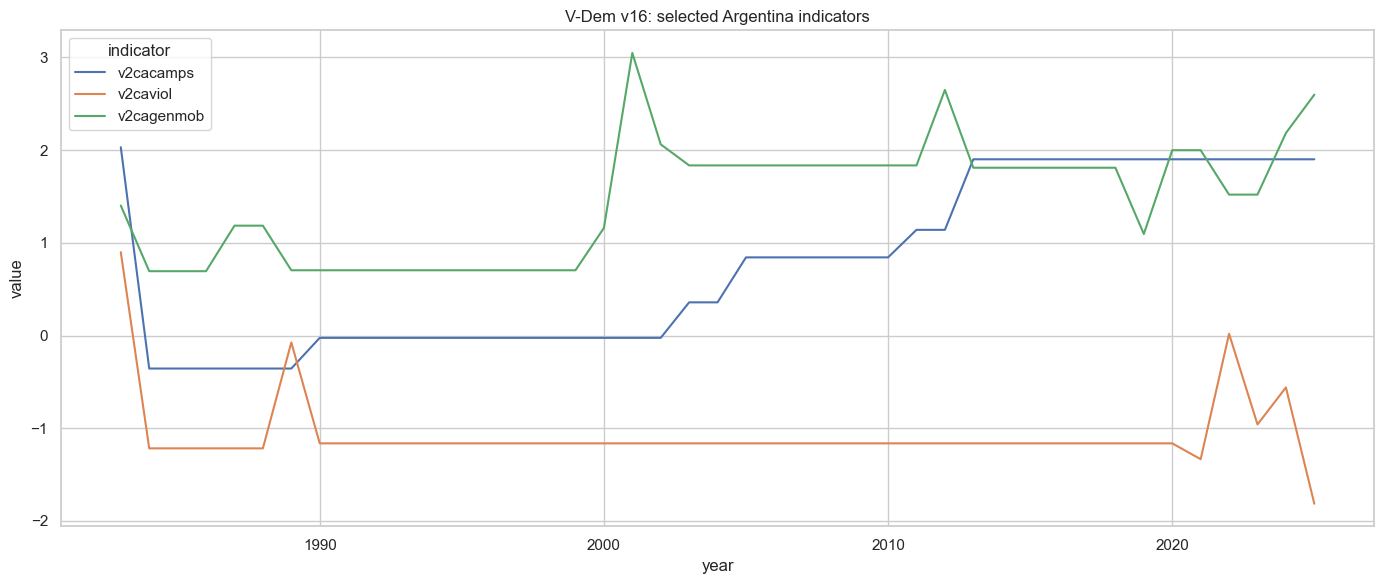

In [12]:
plot_vars = [c for c in selected if c in vdem_arg and pd.api.types.is_numeric_dtype(vdem_arg[c])]
if plot_vars:
    long_vdem = vdem_arg[["year"] + plot_vars].melt("year", var_name="indicator", value_name="value").dropna()
    display(long_vdem.groupby("indicator")["value"].agg(["count","min","max","mean"]).sort_values("count", ascending=False).head(30))
    top_vars = long_vdem["indicator"].value_counts().head(8).index
    plt.figure(figsize=(14, 6))
    sns.lineplot(data=long_vdem[long_vdem.indicator.isin(top_vars)], x="year", y="value", hue="indicator")
    plt.title("V-Dem v16: selected Argentina indicators")
    plt.tight_layout()
    plt.show()


In [13]:
# Codificamos cada indice segun sus valores de referencia en el codebook de V-Dem. Se documenta la interpretacion de cada indice en el diccionario VDEM_INDICATORS.
import numpy as np

labels_scale = [0, 1, 2, 3, 4]

bins_v2caviol_extended = [-np.inf, -1.63, -0.19, 0.89, 1.87, np.inf]

vdem_arg["v2caviol_scale"] = pd.cut(
    vdem_arg["v2caviol"],
    bins=bins_v2caviol_extended,
    labels=labels_scale,
    include_lowest=True,
)

bins_v2cacamps_extended = [-np.inf, -2.13, -0.83, 0.17, 1.34, np.inf]

vdem_arg["v2cacamps_scale"] = pd.cut(
    vdem_arg["v2cacamps"],
    bins=bins_v2cacamps_extended,
    labels=labels_scale,
    include_lowest=True,
)

bins_v2cagenmob_extended = [-np.inf, -1.4, -0.23, 0.35, 1.56, np.inf]

vdem_arg["v2cagenmob_scale"] = pd.cut(
    vdem_arg["v2cagenmob"],
    bins=bins_v2cagenmob_extended,
    labels=labels_scale,
    include_lowest=True,
)


In [14]:
vdem_arg.tail(15)

,country_name,country_text_id,country_id,year,historical_date,v2cacamps,v2caviol,v2cagenmob,v2caviol_scale,v2cacamps_scale,v2cagenmob_scale
222,Argentina,ARG,37,2011,2011-12-31,1.140,-1.163,1.835,1,3,4
223,Argentina,ARG,37,2012,2012-12-31,1.140,-1.163,2.649,1,3,4
224,Argentina,ARG,37,2013,2013-12-31,1.901,-1.163,1.810,1,4,4
225,Argentina,ARG,37,2014,2014-12-31,1.901,-1.163,1.810,1,4,4
226,Argentina,ARG,37,2015,2015-12-31,1.901,-1.163,1.810,1,4,4
227,Argentina,ARG,37,2016,2016-12-31,1.901,-1.163,1.810,1,4,4
228,Argentina,ARG,37,2017,2017-12-31,1.901,-1.163,1.810,1,4,4
229,Argentina,ARG,37,2018,2018-12-31,1.901,-1.163,1.810,1,4,4
230,Argentina,ARG,37,2019,2019-12-31,1.901,-1.163,1.095,1,4,3
231,Argentina,ARG,37,2020,2020-12-31,1.901,-1.163,1.999,1,4,4


### v2caviol
* **Nivel 0** (Rango de `-3.43` a `-1.63`): En absoluto. Los actores no estatales no utilizaron violencia política.

* **Nivel 1** (Rango de `-1.63` a `-0.19`): Raro. Los actores no estatales raramente utilizaron violencia política.

* **Nivel 2** (Rango de `-0.19` a `0.89`): Ocasionalmente. Los actores no estatales utilizaron violencia política de manera ocasional.

* **Nivel 3** (Rango de `0.89` a `1.87`): Frecuentemente. Los actores no estatales utilizaron violencia política de manera frecuente.

* **Nivel 4** (Rango de `1.87` a `4.32`): A menudo. Los actores no estatales utilizaron violencia política muy a menudo.

### v2cacamps
* **Nivel 0** (Rango de `-3.81` a `-2.13`): En absoluto. Los simpatizantes de bandos políticos opuestos se relacionan de forma amigable.

* **Nivel 1** (Rango de `-2.13` a `-0.83`): Principalmente no. Es más probable que interactúen de forma amigable que hostil.

* **Nivel 2** (Rango de `-0.83` a `0.17`): Un poco. Tienen la misma probabilidad de interactuar de forma amigable o hostil.

* **Nivel 3** (Rango de `0.17` a `1.34`): Grado notorio. Es más probable que interactúen de forma hostil que amigable.

* **Nivel 4** (Rango de `1.34` a `3.94`): Gran escala. Generalmente se relacionan de manera hostil.

### v2cagenbomb
* **Nivel 0** (Rango de `-3.57` a `-1.40`): Nula. Prácticamente no han ocurrido eventos de movilización.

* **Nivel 1** (Rango de `-1.40` a `-0.23`): Baja. Han ocurrido varios eventos a pequeña escala.

* **Nivel 2** (Rango de `-0.23` a `0.35`): Moderada. Han ocurrido muchos eventos a pequeña escala.

* **Nivel 3** (Rango de `0.35` a `1.56`): Alta. Han ocurrido varios eventos tanto a gran escala como a pequeña escala.

* **Nivel 4** (Rango de `1.56` a `4.10`): Muy alta. Han ocurrido muchos eventos tanto a gran escala como a pequeña escala.

## DINE - Electoral results API

This section integrates the historical DINE endpoint using `dine_api.py` and the conventions documented in `dine_reference.md`. The example query corresponds to one polling station in 2019; change the parameters to explore another election or geographic scope.


In [ ]:
import sys
from dine_api import fetch_results, normalize_results

DINE_QUERY = {
    "anioEleccion": 2019,
    "tipoEleccion": 1,          # 1 PASO, 2 generales, 3 segunda vuelta
    "categoriaId": 2,           # 1 presidente, 2 senador nacional, 3 diputado nacional
    "tipoRecuento": 1,          # 1 provisorio, 2 definitivo
    "distritoId": 1,
    "seccionProvincialId": 0,
    "seccionId": 3,
    "circuitoId": "000039",
    "mesaId": 1244,
}

try:
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))


    dine_payload, dine_url = fetch_results(
        year=DINE_QUERY["anioEleccion"],
        election_type=DINE_QUERY["tipoEleccion"],
        category_id=DINE_QUERY["categoriaId"],
        recount_type=DINE_QUERY["tipoRecuento"],
        district_id=DINE_QUERY["distritoId"],
        provincial_section_id=DINE_QUERY["seccionProvincialId"],
        section_id=DINE_QUERY["seccionId"],
        circuit_id=DINE_QUERY["circuitoId"],
        mesa_id=DINE_QUERY["mesaId"],
    )
    dine_rows = normalize_results(
        payload=dine_payload,
        year=DINE_QUERY["anioEleccion"],
        election_type=DINE_QUERY["tipoEleccion"],
        category_id=DINE_QUERY["categoriaId"],
        district_id=DINE_QUERY["distritoId"],
        section_id=DINE_QUERY["seccionId"],
        circuit_id=DINE_QUERY["circuitoId"],
        mesa_id=DINE_QUERY["mesaId"],
    )
    dine = pd.DataFrame(dine_rows)
    print("Request:", dine_url)
    print("Rows:", dine.shape)
    display(dine.head())
except Exception as exc:
    dine_payload, dine_url, dine = None, None, pd.DataFrame()
    print(f"DINE query failed: {exc}")
    print("Check the election/category/geography IDs or network access.")


DINE query failed: name 'fetch_results' is not defined
Check the election/category/geography IDs or network access.


In [16]:
if not dine.empty:
    state_cols = [
        "year", "election_type", "category_id", "district_id",
        "section_id", "circuit_id", "mesa_id", "electores",
        "votantes", "participacion_pct", "mesas_totalizadas_pct",
    ]
    display(dine[state_cols].drop_duplicates())
    display(dine.groupby("vote_type")[["votes", "blank_votes", "null_votes", "contested_votes"]].sum(numeric_only=True))
    print("Quality checks:")
    print("votantes <= electores:", (dine["votantes"] <= dine["electores"]).all())
    print("participation range:", dine["participacion_pct"].min(), dine["participacion_pct"].max())


In [17]:
if not dine.empty:
    positive = dine[dine["vote_type"].eq("agrupacion")].sort_values("votes", ascending=False).head(10)
    plt.figure(figsize=(10, 5))
    sns.barplot(data=positive, x="votes", y="group_name", color="#2f6690")
    plt.title("DINE: votos por agrupaci?n en la consulta seleccionada")
    plt.xlabel("Votes")
    plt.ylabel("Agrupaci?n")
    plt.tight_layout()
    plt.show()


### Limitations of this query

- The endpoint returns totalized results for the requested scope, not a complete preservation file.
- `categoriaId`, district, and lower-level geographic IDs must be valid for each election.
- Participation refers to the totalized polling stations in the requested scope; review `mesas_totalizadas_pct`.
- Building provincial maps and national series requires repeating queries by election and district, saving each raw JSON response, and consolidating normalized rows.
